In [1]:
import pandas as pd
import numpy as np

# Load cleaned data
df = pd.read_csv(r"C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\data\processed\SkySafeDB_cleaned.csv")
print("Loaded:", df.shape)
df.head()

Loaded: (231895, 17)


,SPECIES,SIZE,AIRCRAFT,AC_MASS,NUM_ENGS,TYPE_ENG,PHASE_OF_FLIGHT,HEIGHT,SPEED,INCIDENT_MONTH,TIME_OF_DAY,STATE,SKY,COST_REPAIRS,INCIDENT_YEAR,INDEX_NR,IS_DAMAGE
0,Unknown bird - medium,Medium,B-757-200,4.0,2.0,D,Take-off Run,0.0,140.0,7,Unknown,NE,Unknown,0.0,1996,608244,0.0
1,Unknown bird - medium,Medium,A-320,4.0,2.0,D,Approach,1000.0,140.0,7,Unknown,DC,Unknown,0.0,1996,608245,0.0
2,Unknown bird - medium,Medium,A-320,4.0,2.0,D,Climb,5000.0,140.0,7,Unknown,NY,Unknown,0.0,1996,608246,1.0
3,Unknown bird - medium,Medium,B-727-100,4.0,3.0,D,Take-off Run,0.0,100.0,5,Day,TX,No Cloud,0.0,1991,608247,0.0
4,Unknown bird - medium,Medium,B-737-500,4.0,2.0,D,Landing Roll,0.0,140.0,7,Unknown,MO,Unknown,0.0,1995,608249,0.0


In [2]:
# FEATURE DERIVATION (Requirement #2)

# 1. SEASON from month
# Justification: Bird migration patterns are seasonal. Season is more generalizable than raw month.
def get_season(month):
    if month in [12, 1, 2]: return 'Winter'
    elif month in [3, 4, 5]: return 'Spring'
    elif month in [6, 7, 8]: return 'Summer'
    else: return 'Fall'

df['SEASON'] = df['INCIDENT_MONTH'].apply(get_season)

# 2. TIME_BAND from TIME_OF_DAY
# Justification: Raw TIME_OF_DAY has inconsistent labels. We standardize to Day vs Night for clearer signal.
def get_time_band(t):
    if pd.isna(t): return 'Unknown'
    t = str(t).lower()
    if t in ['day', 'dawn', 'dusk']: return 'Day'
    elif t == 'night': return 'Night'
    else: return 'Unknown'

df['TIME_BAND'] = df['TIME_OF_DAY'].apply(get_time_band)

# 3. HEIGHT_BAND from HEIGHT
# Justification: Engine ingestion risk differs dramatically by altitude band. Raw height is continuous noise.
def get_height_band(h):
    if h <= 500: return 'Low'
    elif h <= 3000: return 'Medium'
    else: return 'High'

df['HEIGHT_BAND'] = df['HEIGHT'].apply(get_height_band)

# 4. ENGINE_BIN from NUM_ENGS
# Justification: Redundancy matters. 1-engine plane vs 2-engine vs 3+ engine planes have different damage profiles.
def get_engine_bin(n):
    if n == 1: return '1'
    elif n == 2: return '2'
    else: return '3+'

df['ENGINE_BIN'] = df['NUM_ENGS'].apply(get_engine_bin)

print("New features created: SEASON, TIME_BAND, HEIGHT_BAND, ENGINE_BIN")
df[['INCIDENT_MONTH', 'SEASON', 'TIME_OF_DAY', 'TIME_BAND', 'HEIGHT', 'HEIGHT_BAND', 'NUM_ENGS', 'ENGINE_BIN']].head()

New features created: SEASON, TIME_BAND, HEIGHT_BAND, ENGINE_BIN


,INCIDENT_MONTH,SEASON,TIME_OF_DAY,TIME_BAND,HEIGHT,HEIGHT_BAND,NUM_ENGS,ENGINE_BIN
0,7,Summer,Unknown,Unknown,0.0,Low,2.0,2
1,7,Summer,Unknown,Unknown,1000.0,Medium,2.0,2
2,7,Summer,Unknown,Unknown,5000.0,High,2.0,2
3,5,Spring,Day,Day,0.0,Low,3.0,3+
4,7,Summer,Unknown,Unknown,0.0,Low,2.0,2


In [3]:
print("=== SEASON ===")
print(df['SEASON'].value_counts())
print("\n=== TIME_BAND ===")
print(df['TIME_BAND'].value_counts())
print("\n=== HEIGHT_BAND ===")
print(df['HEIGHT_BAND'].value_counts())
print("\n=== ENGINE_BIN ===")
print(df['ENGINE_BIN'].value_counts())

=== SEASON ===
SEASON
Fall      79796
Summer    73157
Spring    56116
Winter    22826
Name: count, dtype: int64

=== TIME_BAND ===
TIME_BAND
Day        120268
Night       59053
Unknown     52574
Name: count, dtype: int64

=== HEIGHT_BAND ===
HEIGHT_BAND
Low       182284
Medium     35285
High       14326
Name: count, dtype: int64

=== ENGINE_BIN ===
ENGINE_BIN
2     203267
1      15784
3+     12844
Name: count, dtype: int64


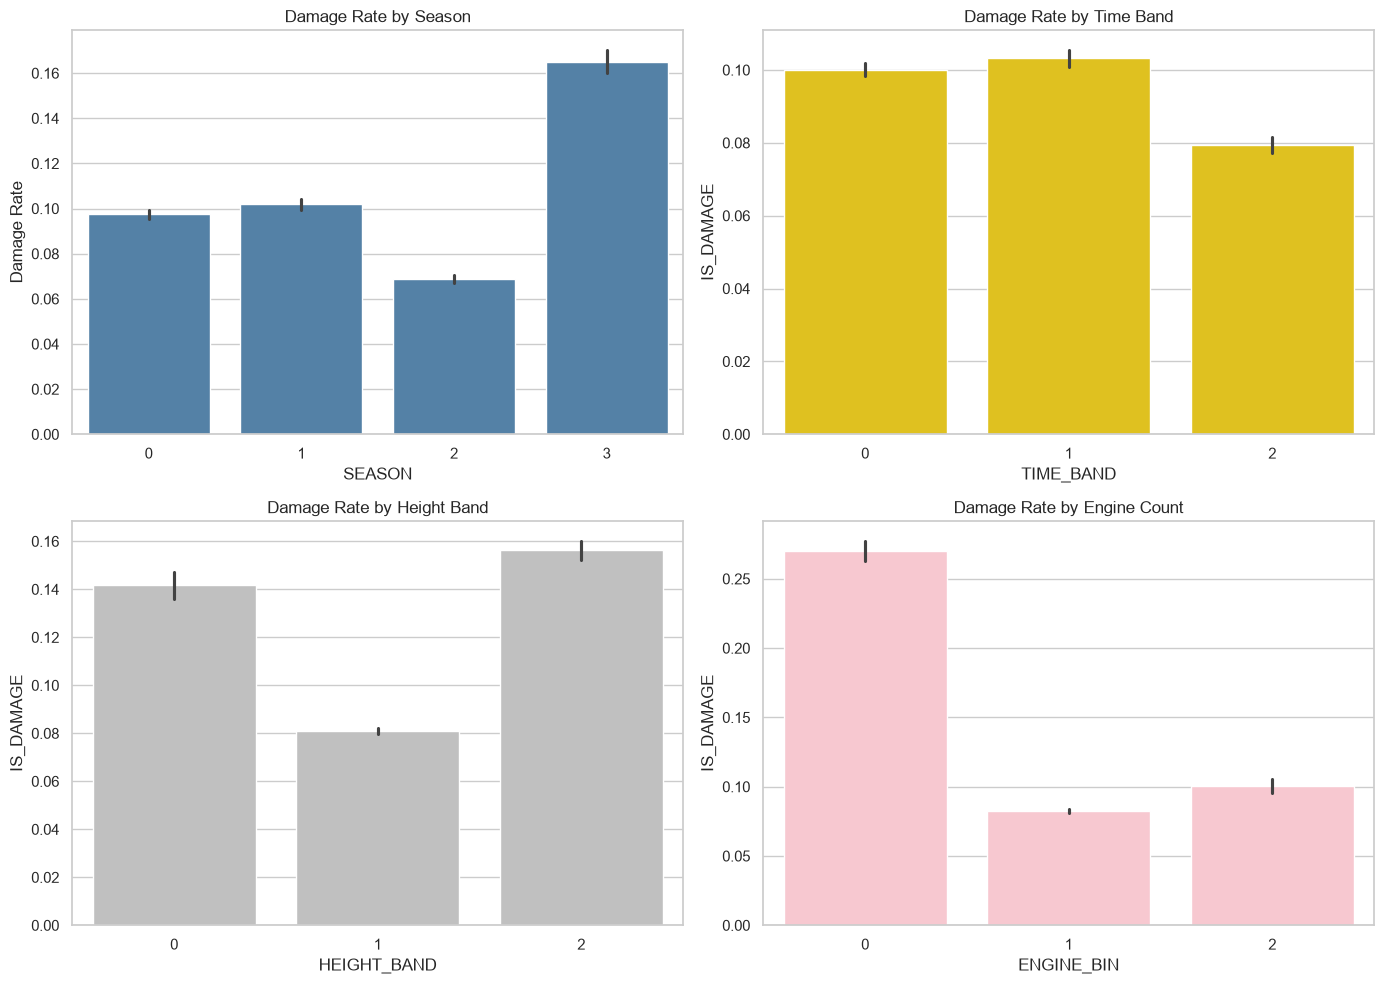

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Season
sns.barplot(data=df, x='SEASON', y='IS_DAMAGE', ax=axes[0,0], color='steelblue')
axes[0,0].set_title('Damage Rate by Season')
axes[0,0].set_ylabel('Damage Rate')

# Time Band
sns.barplot(data=df, x='TIME_BAND', y='IS_DAMAGE', ax=axes[0,1], color='gold')
axes[0,1].set_title('Damage Rate by Time Band')

# Height Band
sns.barplot(data=df, x='HEIGHT_BAND', y='IS_DAMAGE', ax=axes[1,0], color='silver')
axes[1,0].set_title('Damage Rate by Height Band')

# Engine Bin
sns.barplot(data=df, x='ENGINE_BIN', y='IS_DAMAGE', ax=axes[1,1], color='pink')
axes[1,1].set_title('Damage Rate by Engine Count')

plt.tight_layout()
plt.show()

In [5]:
from sklearn.preprocessing import LabelEncoder
import joblib

# The list of features we are actually going to feed the model
feature_cols = [
    'SPECIES', 'SIZE', 'AIRCRAFT', 'AC_MASS', 'NUM_ENGS', 'TYPE_ENG',
    'PHASE_OF_FLIGHT', 'HEIGHT', 'SPEED', 'INCIDENT_MONTH', 'TIME_OF_DAY',
    'STATE', 'SKY', 'SEASON', 'TIME_BAND', 'HEIGHT_BAND', 'ENGINE_BIN'
]

# We will store the encoders so our Streamlit dashboard can use them later
encoders = {}

# Convert all text columns to numbers
for col in feature_cols:
    # If the column is text, we encode it
    if df[col].dtype == 'object' or df[col].dtype == 'string':
        le = LabelEncoder()
        df[col] = le.fit_transform(df[col].astype(str))
        encoders[col] = le  # Save the encoder for later

print(" All text features encoded into numbers.")

# Save the encoders to a file so the dashboard can use them
joblib.dump(encoders, r"C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\models\encoders.pkl")

# Show the first 3 rows of the final dataset
print("\n=== FINAL DATA (First 3 rows) ===")
print(df[feature_cols + ['IS_DAMAGE']].head(3))

 All text features encoded into numbers.

=== FINAL DATA (First 3 rows) ===
   SPECIES  SIZE  AIRCRAFT  AC_MASS  NUM_ENGS  TYPE_ENG  PHASE_OF_FLIGHT  \
0      750     1        84      4.0       2.0         3                9   
1      750     1         5      4.0       2.0         3                0   
2      750     1         5      4.0       2.0         3                2   

   HEIGHT  SPEED  INCIDENT_MONTH  TIME_OF_DAY  STATE  SKY  SEASON  TIME_BAND  \
0     0.0  140.0               7            4     37    3       2          2   
1  1000.0  140.0               7            4     10    3       2          2   
2  5000.0  140.0               7            4     44    3       2          2   

   HEIGHT_BAND  ENGINE_BIN  IS_DAMAGE  
0            1           1        0.0  
1            2           1        0.0  
2            0           1        1.0  


In [6]:
# Save the fully encoded dataset
final_path = r"C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\data\processed\SkySafeDB_final.csv"
df.to_csv(final_path, index=False)

print(f" Final encoded dataset saved to: {final_path}")
print(f"Final Shape: {df.shape[0]} rows, {df.shape[1]} columns")

 Final encoded dataset saved to: C:\Users\sushm\OneDrive\Desktop\SEM 5\ML\SKYSAFE\data\processed\SkySafeDB_final.csv
Final Shape: 231895 rows, 21 columns
